# House Prices Project

Team: Jasper Nash, Jaden Kwon, Akhil Lewis

Kaggle competition: [Regression for house prices](https://www.kaggle.com/competitions/regression-for-house-prices)

The goal is to predict SalePrice for houses in Ames, Iowa. Kaggle scores it with RMSE (basically how many dollars
off we are on average), so lower is better. We started with really simple models and kept adding stuff to see
what helped.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PolynomialFeatures, StandardScaler

## Loading the data

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)
train.head()

(1200, 81) (260, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Looking at the data

First we checked which columns are most related to price. OverallQual and GrLivArea (living area) were the top
two which makes sense.

In the scatter plot theres a house on the far right that is really big but sold super cheap. It turns out it
was sold before it was finished, so it's kind of a weird sale. We took out houses over 4500 sq ft so it doesn't
mess up the model.

In [3]:
train.select_dtypes("number").corr()["SalePrice"].sort_values(ascending=False).head(10)

SalePrice       1.000000
OverallQual     0.789142
GrLivArea       0.740379
TotalBsmtSF     0.641917
GarageCars      0.640961
GarageArea      0.623329
1stFlrSF        0.618556
FullBath        0.571867
TotRmsAbvGrd    0.559435
YearBuilt       0.523194
Name: SalePrice, dtype: float64

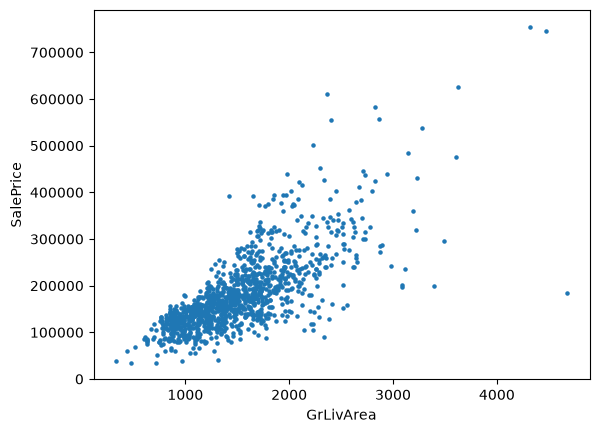

In [4]:
plt.scatter(train["GrLivArea"], train["SalePrice"], s=5)
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.show()

train = train[train["GrLivArea"] < 4500]

## Picking features

We picked some columns that seemed important. There are 3 kinds:
- number columns: just fill in missing values with the average
- quality columns (Po, Fa, TA, Gd, Ex): these have an order so we used OrdinalEncoder. If there's no basement
  the rating is missing so we fill it with "None" which counts as the lowest
- category columns: neighborhood and sale condition dont have an order so we used OneHotEncoder

In [5]:
numeric_cols = ["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "YearBuilt", "YearRemodAdd",
                "FullBath", "Fireplaces", "LotArea", "BsmtFinSF1", "OverallCond"]
quality_cols = ["ExterQual", "KitchenQual", "BsmtQual"]
category_cols = ["Neighborhood", "SaleCondition"]
quality_order = ["None", "Po", "Fa", "TA", "Gd", "Ex"]

features = numeric_cols + quality_cols + category_cols
X = train[features]
y = train["SalePrice"]

## Train/test split

We split the training data so 25% is held out for testing. That way we can see how the model does on houses it
hasn't seen before, which is what Kaggle is doing.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

## Baselines

Super simple models first so we have something to compare to: guessing the average price for every house, and
a linear regression with only OverallQual.

In [7]:
guess = np.full(len(y_test), y_train.mean())
print("guess the average:", round(rmse(y_test, guess)))

lr = LinearRegression()
lr.fit(X_train[["OverallQual"]], y_train)
print("just OverallQual:", round(rmse(y_test, lr.predict(X_test[["OverallQual"]]))))

guess the average: 79207
just OverallQual: 47945


## Using all the features

We put everything in a pipeline so the encoding happens automatically, and it does the same thing to the Kaggle
test data later. We made it a function so we can change the polynomial degree.

In [8]:
def build_model(degree):
    # scaling first so the polynomial numbers dont get crazy big
    numeric = make_pipeline(SimpleImputer(), StandardScaler(), PolynomialFeatures(degree, include_bias=False))
    quality = make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                            OrdinalEncoder(categories=[quality_order] * len(quality_cols)))
    transformer = make_column_transformer(
        (numeric, numeric_cols),
        (quality, quality_cols),
        (OneHotEncoder(handle_unknown="ignore"), category_cols),
    )
    return make_pipeline(transformer, LinearRegression())

## Trying polynomial degrees

We tried degree 1, 2 and 3 and looked at the train and test error for each.

degree 1 train: 27921 test: 26421
degree 2 train: 19588 test: 22527


degree 3 train: 12838 test: 38914


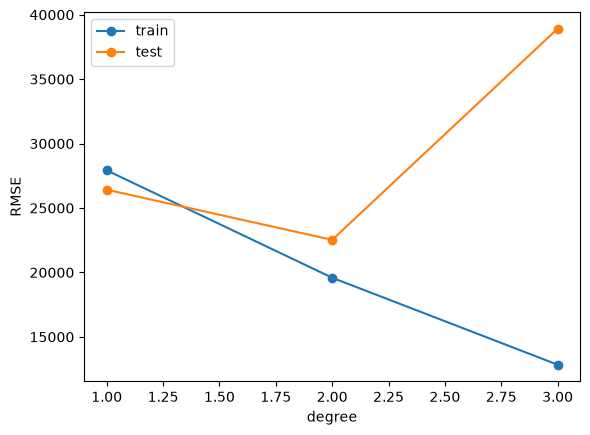

In [9]:
train_errors = []
test_errors = []
for d in [1, 2, 3]:
    model = build_model(d)
    model.fit(X_train, y_train)
    train_err = rmse(y_train, model.predict(X_train))
    test_err = rmse(y_test, model.predict(X_test))
    train_errors.append(train_err)
    test_errors.append(test_err)
    print("degree", d, "train:", round(train_err), "test:", round(test_err))

plt.plot([1, 2, 3], train_errors, marker="o", label="train")
plt.plot([1, 2, 3], test_errors, marker="o", label="test")
plt.xlabel("degree")
plt.ylabel("RMSE")
plt.legend()
plt.show()

Degree 2 was better than degree 1. Degree 3 has the lowest train error but the test error got way worse, so
it's overfitting (it basically memorized the training houses).

## Trying log(price)

We read that a lot of people predict log(SalePrice) instead of the price, since prices are skewed (a few really
expensive houses) and being off by $20k matters more on a cheap house than an expensive one. So we fit on
np.log(y) and then use np.exp to turn the predictions back into dollars.

In [10]:
for d in [1, 2]:
    model = build_model(d)
    model.fit(X_train, np.log(y_train))
    preds = np.exp(model.predict(X_test))
    print("log price, degree", d, "test:", round(rmse(y_test, preds)))

log price, degree 1 test: 20783
log price, degree 2 test: 20979


This was the best so far. Degree 1 and 2 were about the same so we just went with degree 1 since it's simpler.

**Final model: linear regression on log(price), degree 1**

## Making the submission

Now we fit the final model on all the training data and predict the test houses. The Id is just the row number
(0 to 259) like the sample submission.

In [11]:
final_model = build_model(1)
final_model.fit(X, np.log(y))
predictions = np.exp(final_model.predict(test[features]))

submission = pd.DataFrame({"Id": test.index, "SalePrice": predictions})
submission.to_csv("submissions/submission.csv", index=False)
submission.head()

,Id,SalePrice
0,0,94586.369569
1,1,192804.011720
2,2,136492.464573
3,3,209160.632270
4,4,139836.299478


## Results

| Submission | Kaggle score |
|---|---|
| First submission (Ridge regression) | 25,571 |
| Final model | 24,483 |

What we learned:
- adding more features helped a lot compared to just OverallQual
- more complicated isn't always better, degree 3 overfit
- predicting log(price) worked better than the polynomial stuff

If we had more time we would try more features and other models like Ridge or Lasso.